# 1. Esplorazione, degradazioni e split

EuroSAT viene scaricato in `data/`, esclusa da Git. Le degradazioni sono applicate dopo lo split.


In [4]:
# Counter conta quante immagini appartengono a ciascuna classe EuroSAT.
from collections import Counter

# Path costruisce percorsi portabili, indipendenti dal sistema operativo.
from pathlib import Path

# sys.path verra esteso piu avanti per importare il codice locale del progetto.
import sys

# Matplotlib serve per visualizzare le immagini e gli effetti del degrado.
import matplotlib.pyplot as plt

# PyTorch gestisce tensori, dataset e suddivisioni successive.
import torch

# train_test_split crea partizioni casuali, con la possibilita di mantenerle stratificate.
from sklearn.model_selection import train_test_split

# ToTensor converte un'immagine PIL in un tensore PyTorch con valori in [0, 1].
from torchvision import transforms

# EuroSAT scarica o legge il dataset di immagini satellitari organizzato per classi.
from torchvision.datasets import EuroSAT

# Cerchiamo la radice del repository partendo dalla cartella corrente.
# Il ciclo permette di eseguire il notebook sia dalla repo sia dalla cartella notebooks.
ROOT = Path.cwd()
while not (ROOT / "README.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Rendiamo importabile la cartella src, dove si trova l'implementazione del progetto.
sys.path.insert(0, str(ROOT / "src"))

# Importiamo le funzioni che applicano rumore, sfocatura e controllo della casualita.
from eurosat_denoising.utils import add_blur, add_gaussian_noise, seed_everything

# Usiamo un seme fisso per ottenere risultati riproducibili tra esecuzioni.
seed_everything(42)

# Carichiamo EuroSAT nella cartella data; download=True scarica i dati se mancanti.
dataset = EuroSAT(root=ROOT / "data", download=True)

# Stampiamo alcune proprieta di base per verificare che il dataset sia stato letto correttamente.
print("Immagini:", len(dataset))
print("Classi:", dataset.classes)
print("Dimensione prima immagine:", dataset[0][0].size)

# dataset.targets contiene l'indice numerico della classe di ogni immagine.
# Convertiamo gli indici nei nomi leggibili per ottenere la distribuzione per classe.
print("Distribuzione:", {dataset.classes[k]: v for k, v in Counter(dataset.targets).items()})

Immagini: 27000
Classi: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Dimensione prima immagine: (64, 64)
Distribuzione: {'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000}


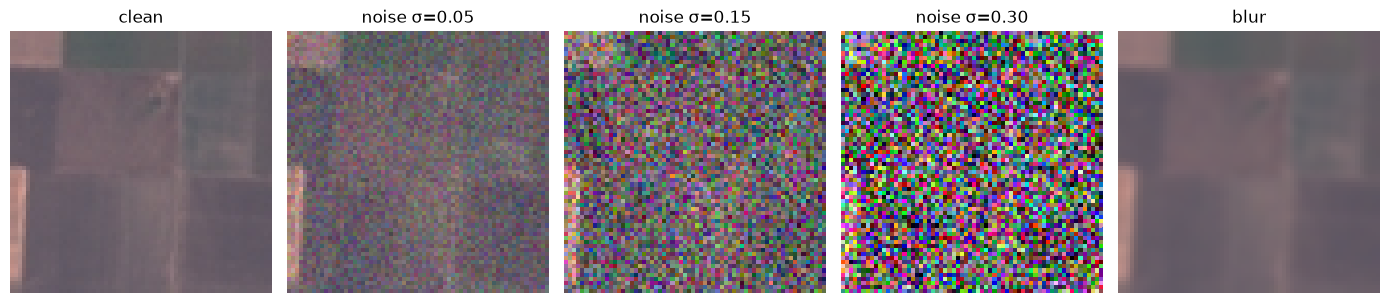

In [5]:
image, _ = dataset[0]
clean = transforms.ToTensor()(image)

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
examples = [
    (clean, "clean"),
    (add_gaussian_noise(clean, 0.05), "noise σ=0.05"),
    (add_gaussian_noise(clean, 0.15), "noise σ=0.15"),
    (add_gaussian_noise(clean, 0.30), "noise σ=0.30"),
    (add_blur(clean), "blur"),
]
for axis, (example, title) in zip(axes, examples):
    axis.imshow(example.permute(1, 2, 0))
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()


In [6]:
indices = list(range(len(dataset)))
labels = list(dataset.targets)

train_indices, remainder_indices, _, remainder_labels = train_test_split(
    indices,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels,
)
val_indices, test_indices = train_test_split(
    remainder_indices,
    test_size=0.50,
    random_state=42,
    stratify=remainder_labels,
)

train = torch.utils.data.Subset(dataset, train_indices)
val = torch.utils.data.Subset(dataset, val_indices)
test = torch.utils.data.Subset(dataset, test_indices)
print("split stratificato:", len(train), len(val), len(test), "seed=42")


split stratificato: 18900 4050 4050 seed=42
